Only modelling for outsourcing costs

Experiment test dataset to 30

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *

import warnings
warnings.filterwarnings("ignore")

In [2]:
# set global color palette or styles
sns.set_palette('Blues_d')

In [3]:
%%html
<style type="text/css">
.findings {background-color: #cdf7f7; padding: 15px;}
.notes {background-color: #d8f5c4; padding: 15px;}
</style>

# 1. Load data

In [4]:
data = pd.read_csv('capstone_outsourcing_df.csv')

In [5]:
data.head()

,services,payment_date,payment_amount
0,CONTRACTOR COSTS,2015-07-14,4.801811
1,CONTRACTOR COSTS,2015-07-21,10.156949
2,CONTRACTOR COSTS,2015-07-28,4.493026
3,CONTRACTOR COSTS,2015-08-04,9.553150
4,CONTRACTOR COSTS,2015-08-11,5.237410


In [6]:
data.shape

(1859, 3)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1859 entries, 0 to 1858
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   services        1859 non-null   object 
 1   payment_date    1859 non-null   object 
 2   payment_amount  1859 non-null   float64
dtypes: float64(1), object(2)
memory usage: 43.7+ KB


In [8]:
data['payment_date'] = pd.to_datetime(data['payment_date'], format = '%Y-%m-%d', errors = 'coerce')

In [9]:
data['payment_date']

0      2015-07-14
1      2015-07-21
2      2015-07-28
3      2015-08-04
4      2015-08-11
          ...    
1854   2026-06-16
1855   2026-06-19
1856   2026-06-23
1857   2026-06-25
1858   2026-06-29
Name: payment_date, Length: 1859, dtype: datetime64[ns]

In [10]:
data.nunique()

services             2
payment_date      1249
payment_amount    1849
dtype: int64

In [11]:
# check the date range
period_start = data.payment_date.min()
period_end = data.payment_date.max()

print(f"The DataFrame starts on {period_start} and ends on {period_end}")

The DataFrame starts on 2015-07-14 00:00:00 and ends on 2026-06-29 00:00:00


In [12]:
# create a full date list for the DataFrame
full_date = pd.date_range(start = period_start, end = period_end, freq = 'D')

# create a list of unique descriptions
desc_list = data['services'].unique()

# create a multi-index list
idx = pd.MultiIndex.from_product( [full_date, desc_list], names = ['payment_date', 'services'])

# cross join the DataFrame with date gaps and the full date list
full_df = data.set_index( ['payment_date', 'services']).reindex(idx).reset_index()
full_df = full_df.fillna(0)
full_df.head()

,payment_date,services,payment_amount
0,2015-07-14,CONTRACTOR COSTS,4.801811
1,2015-07-14,LABOUR HIRE COSTS,6.248572
2,2015-07-15,CONTRACTOR COSTS,0.000000
3,2015-07-15,LABOUR HIRE COSTS,0.000000
4,2015-07-16,CONTRACTOR COSTS,0.000000


In [13]:
full_df.shape

(8008, 3)

In [14]:
# create a copy of the DataFrame in case I need to check against the original DataFrame
df = full_df.copy()


In [15]:
# change the column headers to use statsforecast

df = df.rename(columns = {'services':'unique_id', 'payment_date':'ds', 'payment_amount': 'y'})
df = df.sort_values(by = 'ds')
df

,ds,unique_id,y
0,2015-07-14,CONTRACTOR COSTS,4.801811
1,2015-07-14,LABOUR HIRE COSTS,6.248572
2,2015-07-15,CONTRACTOR COSTS,0.000000
3,2015-07-15,LABOUR HIRE COSTS,0.000000
4,2015-07-16,CONTRACTOR COSTS,0.000000
...,...,...,...
8003,2026-06-27,LABOUR HIRE COSTS,0.000000
8004,2026-06-28,CONTRACTOR COSTS,0.000000
8005,2026-06-28,LABOUR HIRE COSTS,0.000000
8006,2026-06-29,CONTRACTOR COSTS,10.701575


# 2. Baseline models

## 2.1 Create baseline models

In [16]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, HistoricAverage, WindowAverage, SeasonalNaive

In [17]:
%%time
horizon1 = 7 # 7 days horizon

models = [
    Naive(),
    HistoricAverage(),
    WindowAverage(window_size = 7),
    SeasonalNaive(season_length = 7)
]

# set the model frequency in months, month-start frequency
baseline_sf = StatsForecast(models = models, freq = 'D')

# fit the whole dataframe to the models
baseline_sf.fit(df = df)

# predict the future 7 days beyond the dataframe
preds = baseline_sf.predict(h = 30)

CPU times: total: 0 ns
Wall time: 7 ms


In [18]:
preds

,unique_id,ds,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,2026-06-30,10.701575,2.886960,4.671383,10.897764
1,CONTRACTOR COSTS,2026-07-01,10.701575,2.886960,4.671383,0.000000
2,CONTRACTOR COSTS,2026-07-02,10.701575,2.886960,4.671383,11.100341
3,CONTRACTOR COSTS,2026-07-03,10.701575,2.886960,4.671383,0.000000
4,CONTRACTOR COSTS,2026-07-04,10.701575,2.886960,4.671383,0.000000
5,CONTRACTOR COSTS,2026-07-05,10.701575,2.886960,4.671383,0.000000
6,CONTRACTOR COSTS,2026-07-06,10.701575,2.886960,4.671383,10.701575
7,CONTRACTOR COSTS,2026-07-07,10.701575,2.886960,4.671383,10.897764
8,CONTRACTOR COSTS,2026-07-08,10.701575,2.886960,4.671383,0.000000
9,CONTRACTOR COSTS,2026-07-09,10.701575,2.886960,4.671383,11.100341


In [19]:
# show the predictions of the baseline models
preds.head()


,unique_id,ds,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,2026-06-30,10.701575,2.88696,4.671383,10.897764
1,CONTRACTOR COSTS,2026-07-01,10.701575,2.88696,4.671383,0.000000
2,CONTRACTOR COSTS,2026-07-02,10.701575,2.88696,4.671383,11.100341
3,CONTRACTOR COSTS,2026-07-03,10.701575,2.88696,4.671383,0.000000
4,CONTRACTOR COSTS,2026-07-04,10.701575,2.88696,4.671383,0.000000


In [20]:
# create a list of unique ids
unique_ids = df['unique_id'].unique()
unique_ids

array(['CONTRACTOR COSTS', 'LABOUR HIRE COSTS'], dtype=object)

CPU times: total: 15.6 ms
Wall time: 28 ms


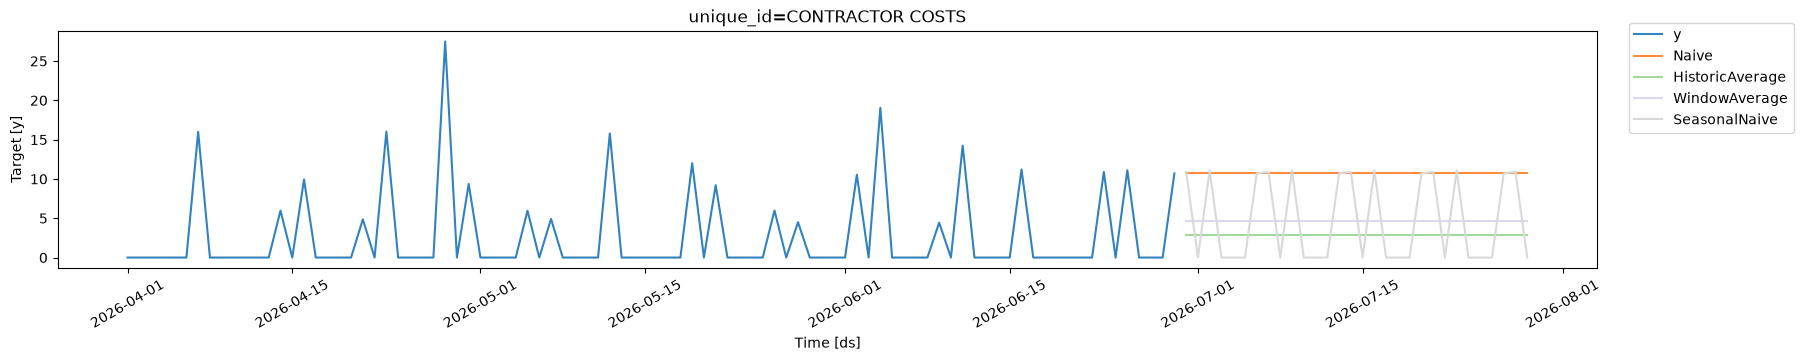

In [21]:
%%time
# plot to forecast of future beyond the dataset
id_n = 0 # select this for plotting Contractor Costs
# id_n = 1 # select this for plotting Labour Hire Costs
plot_series(
    df = df,
    forecasts_df = preds,
    ids = [unique_ids[id_n]],
    max_insample_length = 90,
    palette = 'tab20c'
)

CPU times: total: 15.6 ms
Wall time: 11 ms


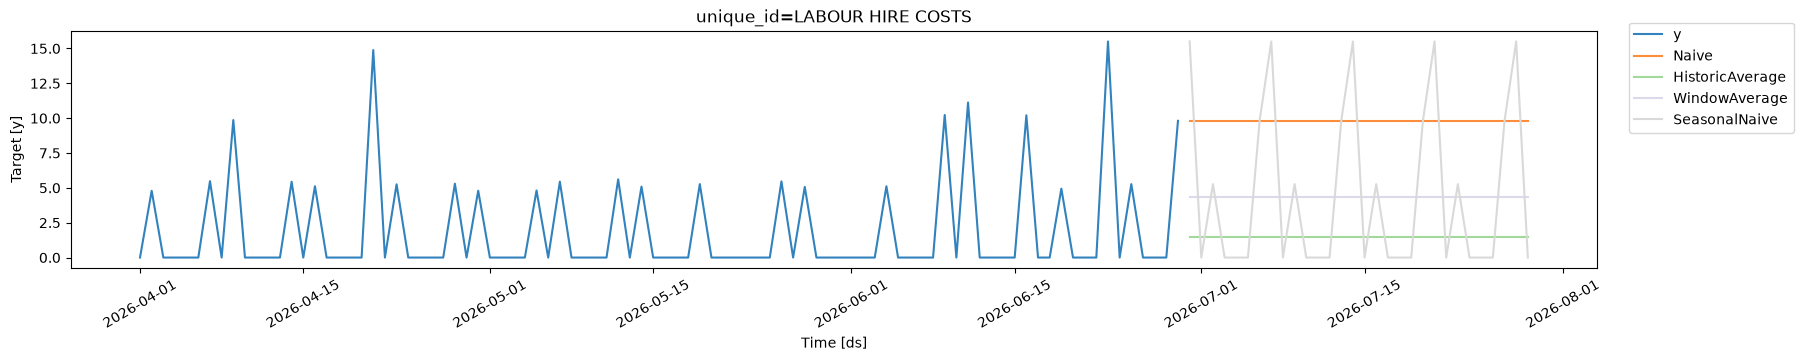

In [22]:
%%time
# plot to forecast of future beyond the dataset
# id_n = 0 # select this for plotting Contractor Costs
id_n = 1 # select this for plotting Labour Hire Costs
plot_series(
    df = df,
    forecasts_df = preds,
    ids = [unique_ids[id_n]],
    max_insample_length = 90,
    palette = 'tab20c'
)

## 2.2 Evaluate baseline models

In [23]:
test = df.groupby('unique_id').tail(30) # test set is the last 30 days in each unique_id
train = df.drop(test.index).reset_index(drop = True)

In [24]:
test.shape # check how many data points in the test set

(60, 3)

In [25]:
test

,ds,unique_id,y
7948,2026-05-31,CONTRACTOR COSTS,0.000000
7949,2026-05-31,LABOUR HIRE COSTS,0.000000
7950,2026-06-01,CONTRACTOR COSTS,0.000000
7951,2026-06-01,LABOUR HIRE COSTS,0.000000
7952,2026-06-02,CONTRACTOR COSTS,10.543937
7953,2026-06-02,LABOUR HIRE COSTS,0.000000
7955,2026-06-03,LABOUR HIRE COSTS,0.000000
7954,2026-06-03,CONTRACTOR COSTS,0.000000
7956,2026-06-04,CONTRACTOR COSTS,19.051596
7957,2026-06-04,LABOUR HIRE COSTS,5.113313


In [26]:
train.shape # check how many data points in the training set

(7948, 3)

In [27]:
train

,ds,unique_id,y
0,2015-07-14,CONTRACTOR COSTS,4.801811
1,2015-07-14,LABOUR HIRE COSTS,6.248572
2,2015-07-15,CONTRACTOR COSTS,0.000000
3,2015-07-15,LABOUR HIRE COSTS,0.000000
4,2015-07-16,CONTRACTOR COSTS,0.000000
...,...,...,...
7943,2026-05-28,LABOUR HIRE COSTS,5.067286
7944,2026-05-29,CONTRACTOR COSTS,0.000000
7945,2026-05-29,LABOUR HIRE COSTS,0.000000
7946,2026-05-30,CONTRACTOR COSTS,0.000000


In [28]:
%%time
horizon2 = 30

baseline_sf.fit(df = train)

preds2 = baseline_sf.predict(h = horizon2) 

eval_df = pd.merge(test, preds2, 'left', ['unique_id','ds'])

CPU times: total: 0 ns
Wall time: 7 ms


In [29]:
preds2

,unique_id,ds,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,2026-05-31,0.0,2.885561,1.497633,0.000000
1,CONTRACTOR COSTS,2026-06-01,0.0,2.885561,1.497633,0.000000
2,CONTRACTOR COSTS,2026-06-02,0.0,2.885561,1.497633,5.986373
3,CONTRACTOR COSTS,2026-06-03,0.0,2.885561,1.497633,0.000000
4,CONTRACTOR COSTS,2026-06-04,0.0,2.885561,1.497633,4.497058
5,CONTRACTOR COSTS,2026-06-05,0.0,2.885561,1.497633,0.000000
6,CONTRACTOR COSTS,2026-06-06,0.0,2.885561,1.497633,0.000000
7,CONTRACTOR COSTS,2026-06-07,0.0,2.885561,1.497633,0.000000
8,CONTRACTOR COSTS,2026-06-08,0.0,2.885561,1.497633,0.000000
9,CONTRACTOR COSTS,2026-06-09,0.0,2.885561,1.497633,5.986373


In [30]:
%%time
evaluation_baseline = evaluate(
    eval_df,
    metrics = [mae] # use Mean Absolute Error to evaluate the errors
)
evaluation_baseline # check the evaluation of rmses from the baseline models


CPU times: total: 15.6 ms
Wall time: 24 ms


,unique_id,metric,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,mae,3.072273,4.418868,3.771169,2.077768
1,LABOUR HIRE COSTS,mae,2.406621,3.077593,3.108588,1.704655


In [31]:
# calculate the average performance of the baseline models across all unique_id
evaluation_baseline_avg = evaluation_baseline.drop(['unique_id'], axis=1).groupby('metric').mean().reset_index()
evaluation_baseline_avg

,metric,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,mae,2.739447,3.748231,3.439878,1.891212


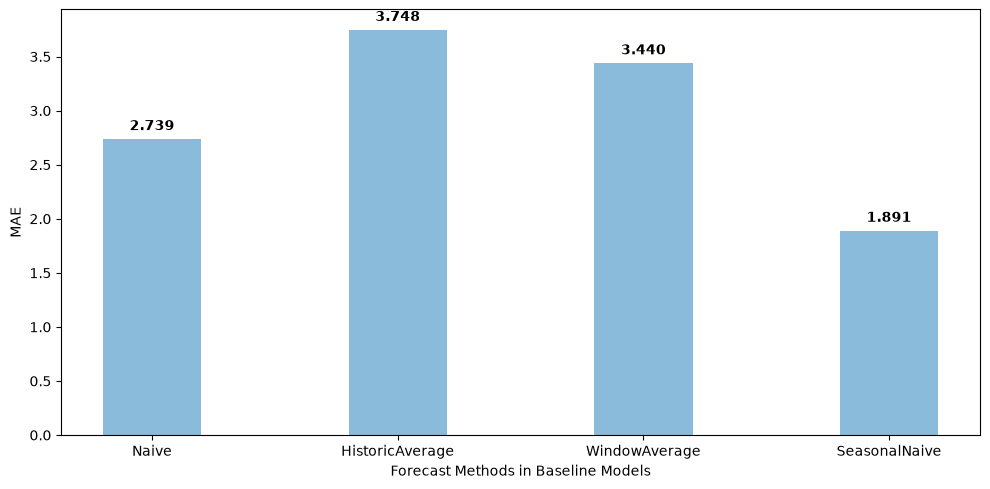

In [32]:
# plot 
methods = evaluation_baseline_avg.columns[1:].tolist()  
values = evaluation_baseline_avg.iloc[0, 1:].tolist() 

plt.figure(figsize=(10, 5))
bars = plt.bar(methods, values, width = 0.4)

for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
             f'{value:.3f}', ha='center', va='bottom', fontweight='bold')

plt.xlabel('Forecast Methods in Baseline Models')
plt.ylabel('MAE')
plt.tight_layout()

plt.show()

# 3. AutoARIMA

In [33]:
from statsforecast.models import AutoARIMA

## 3.1 Create ARIMA and SARIMA Models

In [34]:
%%time
# set up both ARIMA and SARIMA models (add appromximation = True in AutoARIMA modelling  to speed up)

models2 = [
    AutoARIMA(seasonal = False, alias = 'ARIMA', trace = True, stepwise=True),
    AutoARIMA(season_length = 7, alias = 'SARIMA', trace = True, stepwise=True),
] 

# initiate the forecast model
arima_sf = StatsForecast(models = models2, freq = 'D')

# fit the models with small training dataset
arima_sf.fit(df = train)

# calculate predictions
arima_preds = arima_sf.predict(h = horizon2) 

ARIMA(2,1,2) with drift         : inf
ARIMA(0,1,0) with drift         : 28100.9630
ARIMA(1,1,0) with drift         : 26030.4458
ARIMA(0,1,1) with drift         : 24687.9622
ARIMA(0,1,0)                    : 28099.6267
ARIMA(1,1,1) with drift         : 24547.0144
ARIMA(2,1,1) with drift         : 24503.1790
ARIMA(2,1,0) with drift         : 25899.3503
ARIMA(3,1,1) with drift         : 24324.3153
ARIMA(3,1,0) with drift         : 25864.6267
ARIMA(4,1,1) with drift         : 23775.1699
ARIMA(4,1,0) with drift         : 24875.2893
ARIMA(5,1,1) with drift         : 23747.0268
ARIMA(5,1,0) with drift         : 24813.3413
ARIMA(5,1,2) with drift         : 23381.8510
ARIMA(4,1,2) with drift         : 23381.3855
ARIMA(3,1,2) with drift         : 24100.5339
ARIMA(4,1,3) with drift         : 23375.1503
ARIMA(3,1,3) with drift         : inf
ARIMA(5,1,3) with drift         : 23370.9586
ARIMA(5,1,4) with drift         : inf
ARIMA(4,1,4) with drift         : inf
ARIMA(5,1,3)                    : 2336

In [35]:
arima_preds

,unique_id,ds,ARIMA,SARIMA
0,CONTRACTOR COSTS,2026-05-31,2.993840,0.000000e+00
1,CONTRACTOR COSTS,2026-06-01,1.808531,0.000000e+00
2,CONTRACTOR COSTS,2026-06-02,4.835015,1.123160e+01
3,CONTRACTOR COSTS,2026-06-03,1.870227,0.000000e+00
4,CONTRACTOR COSTS,2026-06-04,3.100947,4.642179e+00
5,CONTRACTOR COSTS,2026-06-05,1.826378,0.000000e+00
6,CONTRACTOR COSTS,2026-06-06,2.012885,0.000000e+00
7,CONTRACTOR COSTS,2026-06-07,2.918216,0.000000e+00
8,CONTRACTOR COSTS,2026-06-08,1.965325,0.000000e+00
9,CONTRACTOR COSTS,2026-06-09,3.328670,9.690432e+00


## 3.2 Evaluate a Data Subset with ARIMA, SARIMA and Baseline Models

In [36]:
# merge arima predictions with the previous evaluation dataframe

arima_eval_df = pd.merge(arima_preds, eval_df, 'inner', ['ds', 'unique_id'])

In [37]:
arima_eval_df # check the dataframe

,unique_id,ds,ARIMA,SARIMA,y,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,2026-05-31,2.993840,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
1,CONTRACTOR COSTS,2026-06-01,1.808531,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
2,CONTRACTOR COSTS,2026-06-02,4.835015,1.123160e+01,10.543937,0.0,2.885561,1.497633,5.986373
3,CONTRACTOR COSTS,2026-06-03,1.870227,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
4,CONTRACTOR COSTS,2026-06-04,3.100947,4.642179e+00,19.051596,0.0,2.885561,1.497633,4.497058
5,CONTRACTOR COSTS,2026-06-05,1.826378,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
6,CONTRACTOR COSTS,2026-06-06,2.012885,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
7,CONTRACTOR COSTS,2026-06-07,2.918216,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
8,CONTRACTOR COSTS,2026-06-08,1.965325,0.000000e+00,0.000000,0.0,2.885561,1.497633,0.000000
9,CONTRACTOR COSTS,2026-06-09,3.328670,9.690432e+00,4.434147,0.0,2.885561,1.497633,5.986373


In [38]:
%%time
# evaluate the performance of all 6 models

arima_eval = evaluate(
    arima_eval_df,
    metrics = [mae]
)

arima_eval

CPU times: total: 0 ns
Wall time: 3 ms


,unique_id,metric,ARIMA,SARIMA,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,mae,3.962916,1.774521,3.072273,4.418868,3.771169,2.077768
1,LABOUR HIRE COSTS,mae,2.865681,1.665956,2.406621,3.077593,3.108588,1.704655


In [39]:
# find the mean values of the evaluation

arima_eval_avg = arima_eval.drop(['unique_id'], axis = 1).groupby('metric').mean().reset_index()
arima_eval_avg

,metric,ARIMA,SARIMA,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,mae,3.414299,1.720238,2.739447,3.748231,3.439878,1.891212


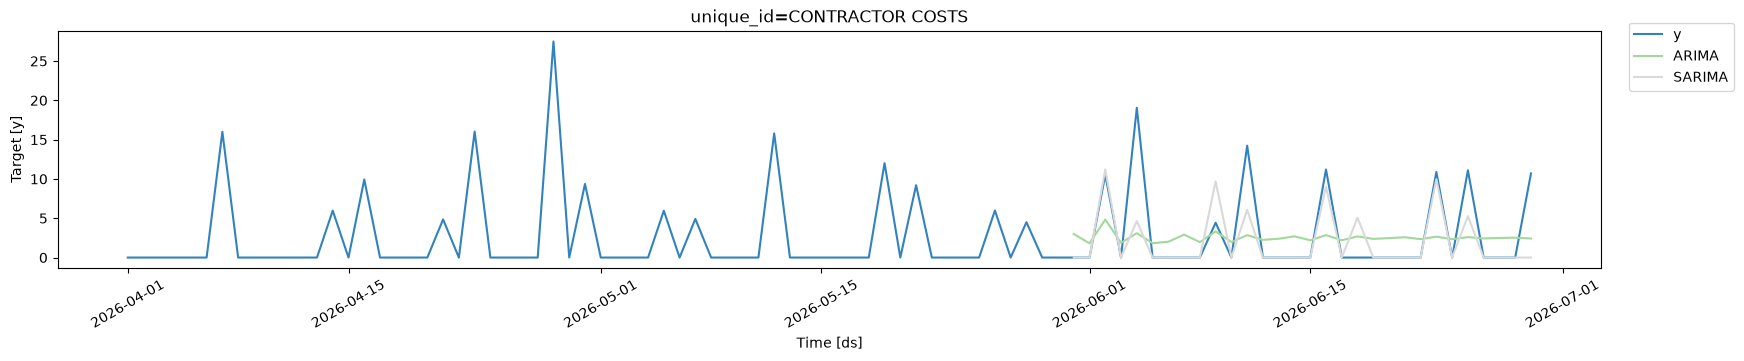

In [40]:
# plot
plot_series(
    df = df,
    forecasts_df = arima_preds[arima_preds['unique_id'] == 'CONTRACTOR COSTS'],
    ids = [unique_ids[0]],
    max_insample_length = 90,
    palette = 'tab20c'
)

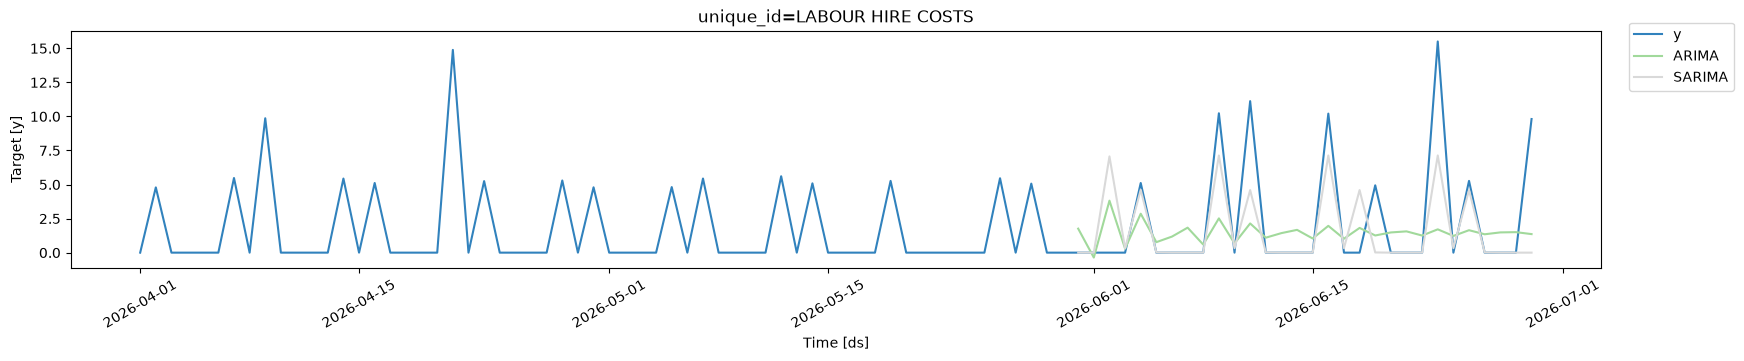

In [41]:
# plot
plot_series(
    df = df,
    forecasts_df = arima_preds[arima_preds['unique_id'] == 'LABOUR HIRE COSTS'],
    ids = ['LABOUR HIRE COSTS'],
    max_insample_length = 90,
    palette = 'tab20c'
)

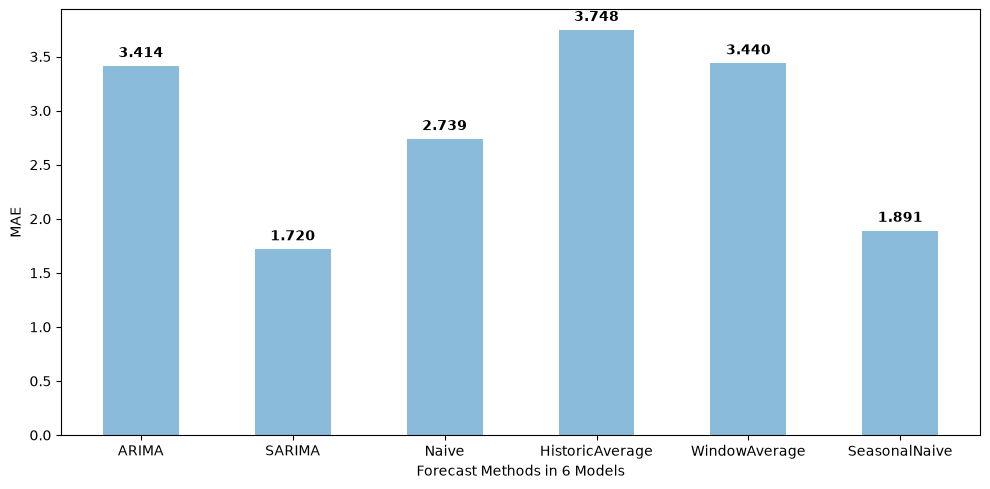

In [42]:
# plot 
methods = arima_eval_avg.columns[1:].tolist()  
values = arima_eval_avg.iloc[0, 1:].tolist() 

plt.figure(figsize=(10, 5))
bars = plt.bar(methods, values, width = 0.5)

for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
             f'{value:.3f}', ha='center', va='bottom', fontweight='bold')

plt.xlabel('Forecast Methods in 6 Models')
plt.ylabel('MAE')
plt.tight_layout()

plt.show()

# 4. SARIMA with Features from Timestamps

In [43]:
from functools import partial
from utilsforecast.feature_engineering import fourier, time_features, pipeline

In [44]:
# create features from day week month

features = [
    partial(fourier, freq = 'D', season_length=7, k=2),
    partial(time_features, freq = 'D', features=["day", "week", "month"])
]

In [45]:
exog_df, futr_exog_df = pipeline(
    df=df,
    features=features,
    freq="D",
    h=0
)

In [46]:
exog_df.shape

(8008, 7)

In [47]:
exog_df.head()

,ds,unique_id,y,sin1_7,sin2_7,cos1_7,cos2_7
0,2015-07-14,CONTRACTOR COSTS,4.801811,0.781832,0.974928,0.623490,-0.222521
1,2015-07-14,LABOUR HIRE COSTS,6.248572,0.781832,0.974928,0.623490,-0.222521
2,2015-07-15,CONTRACTOR COSTS,0.000000,0.974928,-0.433884,-0.222521,-0.900969
3,2015-07-15,LABOUR HIRE COSTS,0.000000,0.974928,-0.433884,-0.222521,-0.900969
4,2015-07-16,CONTRACTOR COSTS,0.000000,0.433884,-0.781831,-0.900969,0.623490


In [48]:
futr_exog_df

""


In [49]:
# futr_exog_df[futr_exog_df['unique_id'] == 'CONTRACTOR COSTS']

In [50]:
# futr_exog_df[futr_exog_df['unique_id'] == 'LABOUR HIRE COSTS']

In [51]:
# create training and test datasets
exog_test = exog_df.groupby('unique_id').tail(30) # test set is the last 30 days in each unique_id
exog_train = exog_df.drop(test.index).reset_index(drop = True)

In [52]:
%%time

models3 = [
    AutoARIMA(season_length=7, alias="SARIMA_time_exog", trace = True, stepwise=True, approximation = True)
]


exog_sf = StatsForecast(models=models3, freq="D")

CPU times: total: 0 ns
Wall time: 0 ns


In [53]:
%%time

# fit the models with small training dataset
exog_sf.fit(df = exog_train)

# calculate predictions
exog_preds = exog_sf.predict(h = horizon2, X_df = exog_test.drop('y', axis = 1)) 

Fitting models using approximations to speed things up
Regression with ARIMA(2,1,2)(1,0,1)[7] errors : inf
Regression with ARIMA(0,1,0)           errors : 27676.7426
Regression with ARIMA(1,1,0)(1,0,0)[7] errors : 24044.0591
Regression with ARIMA(0,1,1)(0,0,1)[7] errors : inf
Regression with ARIMA(0,1,0)           errors : 27674.7366
Regression with ARIMA(1,1,0)           errors : 24450.0805
Regression with ARIMA(1,1,0)(2,0,0)[7] errors : 23741.3319
Regression with ARIMA(1,1,0)(2,0,1)[7] errors : inf
Regression with ARIMA(1,1,0)(1,0,1)[7] errors : inf
Regression with ARIMA(0,1,0)(2,0,0)[7] errors : 25236.1643
Regression with ARIMA(2,1,0)(2,0,0)[7] errors : 23340.5296
Regression with ARIMA(2,1,0)(1,0,0)[7] errors : 23603.8486
Regression with ARIMA(2,1,0)(2,0,1)[7] errors : inf
Regression with ARIMA(2,1,0)(1,0,1)[7] errors : inf
Regression with ARIMA(3,1,0)(2,0,0)[7] errors : 23124.6141
Regression with ARIMA(3,1,0)(1,0,0)[7] errors : 23476.6018
Regression with ARIMA(3,1,0)(2,0,1)[7] erro

In [54]:
exog_preds

,unique_id,ds,SARIMA_time_exog
0,CONTRACTOR COSTS,2026-05-31,-1.524587
1,CONTRACTOR COSTS,2026-06-01,1.506412
2,CONTRACTOR COSTS,2026-06-02,7.444493
3,CONTRACTOR COSTS,2026-06-03,2.231255
4,CONTRACTOR COSTS,2026-06-04,5.301273
5,CONTRACTOR COSTS,2026-06-05,1.278937
6,CONTRACTOR COSTS,2026-06-06,-0.544267
7,CONTRACTOR COSTS,2026-06-07,-1.274317
8,CONTRACTOR COSTS,2026-06-08,1.949495
9,CONTRACTOR COSTS,2026-06-09,6.328480


In [55]:
# merge arima predictions with the previous evaluation dataframe

exog_eval_df = pd.merge(exog_preds, arima_eval_df, 'inner', ['ds', 'unique_id'])

In [ ]:
exog_eval_df

In [56]:
%%time
# evaluate the performance of all 7 models

exog_eval = evaluate(
    exog_eval_df,
    metrics = [mae]
)

exog_eval

CPU times: total: 0 ns
Wall time: 3 ms


,unique_id,metric,SARIMA_time_exog,ARIMA,SARIMA,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,CONTRACTOR COSTS,mae,3.222180,3.962916,1.774521,3.072273,4.418868,3.771169,2.077768
1,LABOUR HIRE COSTS,mae,1.712925,2.865681,1.665956,2.406621,3.077593,3.108588,1.704655


In [57]:
# merge arima predictions with exog predictions

exog_arima_preds = pd.merge(exog_preds, arima_preds, 'inner', ['ds', 'unique_id'])

CPU times: total: 15.6 ms
Wall time: 8 ms


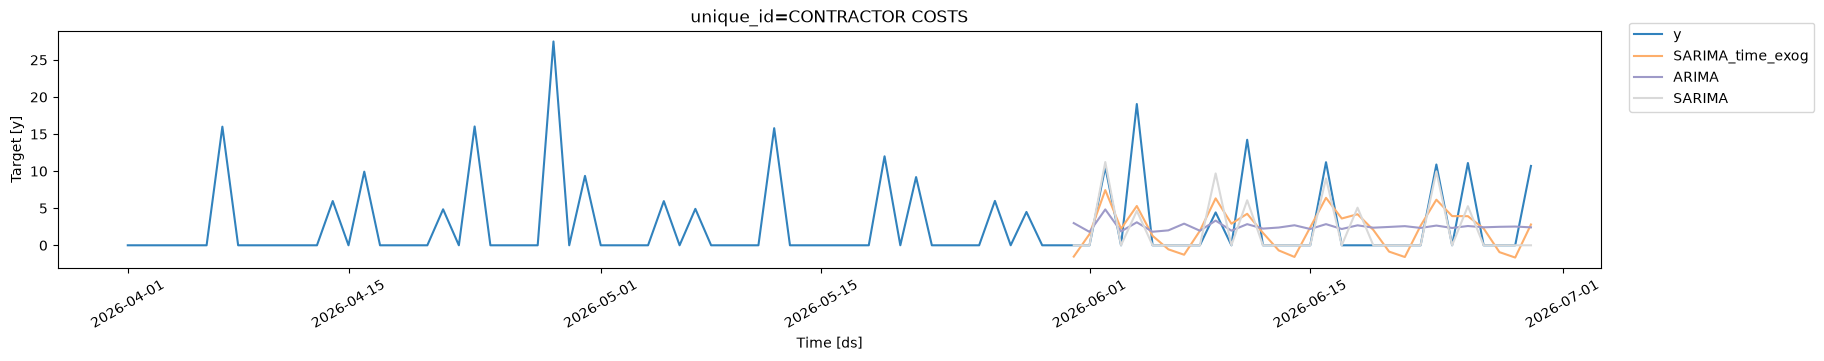

In [58]:
%%time
# plot
plot_series(
    df = exog_df,
    forecasts_df = exog_arima_preds[exog_arima_preds['unique_id'] == 'CONTRACTOR COSTS'],
    ids = ['CONTRACTOR COSTS'],
    max_insample_length = 90,
    palette = 'tab20c'
)

CPU times: total: 15.6 ms
Wall time: 8 ms


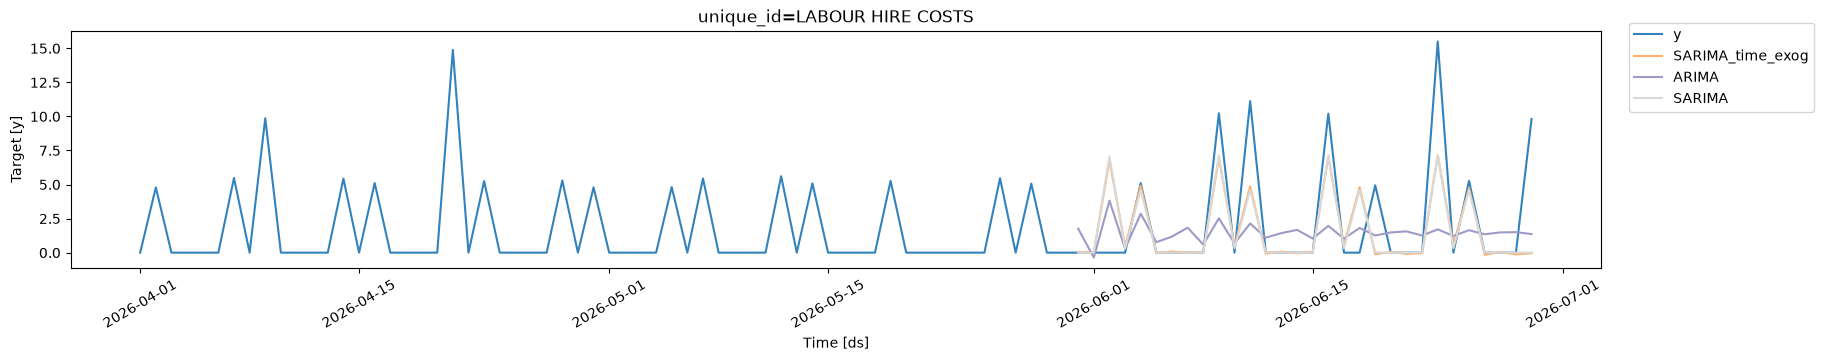

In [59]:
%%time
# plot
plot_series(
    df = exog_df,
    forecasts_df = exog_arima_preds[exog_arima_preds['unique_id'] == 'LABOUR HIRE COSTS'],
    ids = ['LABOUR HIRE COSTS'],
    max_insample_length = 90,
    palette = 'tab20c'
)

In [60]:
# find the mean values of the evaluation

exog_eval_avg = exog_eval.drop(['unique_id'], axis = 1).groupby('metric').mean().reset_index()
exog_eval_avg

,metric,SARIMA_time_exog,ARIMA,SARIMA,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,mae,2.467552,3.414299,1.720238,2.739447,3.748231,3.439878,1.891212


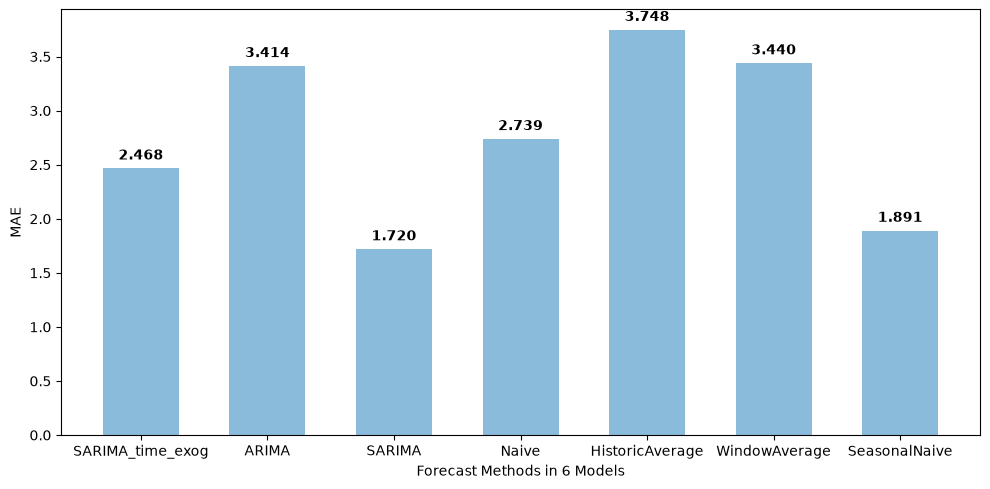

In [61]:
# plot 
methods = exog_eval_avg.columns[1:].tolist()  
values = exog_eval_avg.iloc[0, 1:].tolist() 

plt.figure(figsize=(10, 5))
bars = plt.bar(methods, values, width = 0.6)

for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
             f'{value:.3f}', ha='center', va='bottom', fontweight='bold')

plt.xlabel('Forecast Methods in 6 Models')
plt.ylabel('MAE')
plt.tight_layout()

plt.show()

# 5. Cross Validation of Forecasting 

## 5.1 Build Cross_validation Models

In [62]:
%%time
# select 3 models for cross-validation 

models4 = [
    SeasonalNaive(season_length=7),
    AutoARIMA(seasonal = False, alias = 'ARIMA', trace = True, stepwise=True, approximation = True),
    AutoARIMA(season_length=7, alias="SARIMA", trace = True, stepwise=True, approximation = True)
] 

# initialise the models
sf = StatsForecast(models=models4, freq="D")

# initialise cross-validation
cv_df = sf.cross_validation(
    h=horizon2, # 30 days
    df=df,
    n_windows=8,
    step_size=horizon1, # 7 days
    refit=True
)

# check
cv_df.head()

Fitting models using approximations to speed things up
ARIMA(2,1,2) with drift         : inf
ARIMA(0,1,0) with drift         : 11135.5995
ARIMA(1,1,0) with drift         : 9092.6572
ARIMA(0,1,1) with drift         : 7789.0014
ARIMA(0,1,0)                    : 11133.5976
ARIMA(1,1,1) with drift         : 7628.1746
ARIMA(2,1,1) with drift         : 7597.0606
ARIMA(2,1,0) with drift         : 8964.5318
ARIMA(3,1,1) with drift         : 7408.8409
ARIMA(3,1,0) with drift         : 8931.1546
ARIMA(4,1,1) with drift         : 6863.9856
ARIMA(4,1,0) with drift         : 7955.0678
ARIMA(5,1,1) with drift         : 6847.1636
ARIMA(5,1,0) with drift         : 7894.1512
ARIMA(5,1,2) with drift         : 6485.2376
ARIMA(4,1,2) with drift         : 6477.0035
ARIMA(3,1,2) with drift         : 7184.1474
ARIMA(4,1,3) with drift         : 6469.7657
ARIMA(3,1,3) with drift         : inf
ARIMA(5,1,3) with drift         : 6475.2670
ARIMA(4,1,4) with drift         : inf
ARIMA(3,1,4) with drift         : inf

,unique_id,ds,cutoff,y,SeasonalNaive,ARIMA,SARIMA
0,CONTRACTOR COSTS,2026-04-12,2026-04-11,0.000000,0.000000,6.273086,0.000000e+00
1,CONTRACTOR COSTS,2026-04-13,2026-04-11,0.000000,0.000000,0.903278,0.000000e+00
2,CONTRACTOR COSTS,2026-04-14,2026-04-11,5.969436,15.994706,5.574476,1.203629e+01
3,CONTRACTOR COSTS,2026-04-15,2026-04-11,0.000000,0.000000,0.288112,3.909135e-311
4,CONTRACTOR COSTS,2026-04-16,2026-04-11,9.932994,0.000000,2.607022,3.493638e+00


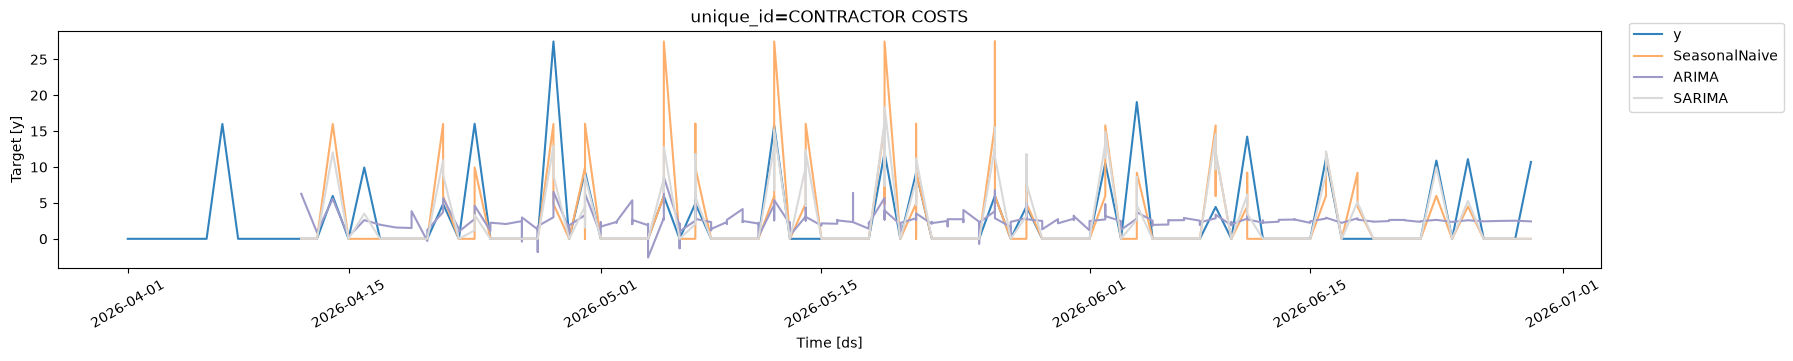

In [63]:
# plot
cv_df_short = cv_df.drop(["y", "cutoff"], axis=1)
plot_series(
    df=df, 
    forecasts_df=cv_df_short[cv_df_short['unique_id'] == 'CONTRACTOR COSTS'], 
    ids=['CONTRACTOR COSTS'], 
    max_insample_length=90, 
    palette="tab20c"
)

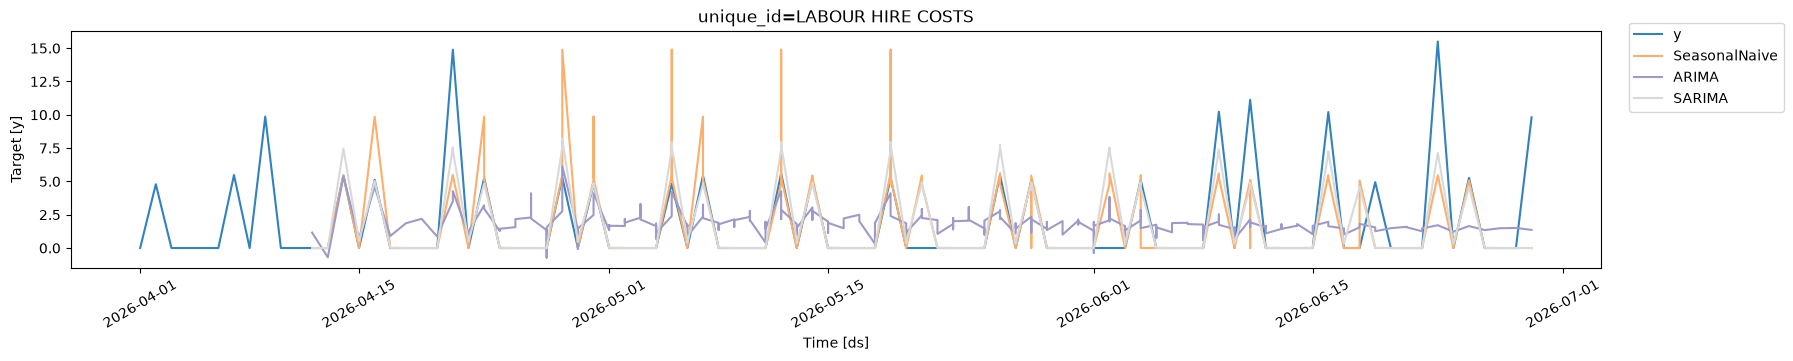

In [64]:
plot_series(
    df=df, 
    forecasts_df=cv_df_short[cv_df_short['unique_id'] == 'LABOUR HIRE COSTS'], 
    ids=['LABOUR HIRE COSTS'], 
    max_insample_length=90, 
    palette="tab20c"
)

## 5.2 Evaluate Cross Validation

In [65]:
cv_eval = evaluate(
    cv_df,
    metrics = [mae]
)

cv_eval

,unique_id,cutoff,metric,SeasonalNaive,ARIMA,SARIMA
0,CONTRACTOR COSTS,2026-04-11,mae,2.764285,3.606654,2.154570
1,LABOUR HIRE COSTS,2026-04-11,mae,0.971661,2.009561,0.592991
2,CONTRACTOR COSTS,2026-04-18,mae,1.802796,3.480447,1.782604
3,LABOUR HIRE COSTS,2026-04-18,mae,0.373047,2.269281,0.583398
4,CONTRACTOR COSTS,2026-04-25,mae,2.748354,3.272056,1.797847
5,LABOUR HIRE COSTS,2026-04-25,mae,1.487061,1.863115,0.628335
6,CONTRACTOR COSTS,2026-05-02,mae,2.968008,2.916100,1.728495
7,LABOUR HIRE COSTS,2026-05-02,mae,0.233134,1.996044,0.582350
8,CONTRACTOR COSTS,2026-05-09,mae,1.475024,3.727606,1.305552
9,LABOUR HIRE COSTS,2026-05-09,mae,0.440328,1.809550,0.696209
